In [1]:
# Celula 1: prepara o ambiente de trabalho para toda a analise.
# - pandas/numpy: manipulacao de dados
# - matplotlib: graficos
# - scikit-learn: validacao cruzada e metricas
# - xgboost: modelo de classificacao
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import TimeSeriesSplit
# from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay,
)

# Instala automaticamente o xgboost apenas se ele nao estiver disponivel.
try:
    from xgboost import XGBClassifier
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    from xgboost import XGBClassifier

# Instala automaticamente o optuna apenas se ele nao estiver disponivel.
try:
    import optuna
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna", "-q"])
    import optuna

# Instala automaticamente o optuna-dashboard apenas se ele nao estiver disponivel.
try:
    import optuna_dashboard
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna-dashboard", "-q"])
    import optuna_dashboard

# Mostra todas as colunas ao inspecionar DataFrames.
pd.set_option("display.max_columns", None)
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [2]:
# Celula 2: leitura da base e preparo das variaveis de entrada.
csv_path = Path("../../tabela_final/table_orders_holidays_ecommerce_events.csv") # Path(r"C:\Users\otavi\OneDrive\Desktop\last-mile-tcc\backend\tabela_final\table_orders_holidays_ecommerce_events.csv")
df = pd.read_csv(csv_path)

target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

df['order_estimated_delivery_date'] = pd.to_datetime(
    df['order_estimated_delivery_date'], utc=True
)

df['order_delivered_carrier_date'] = pd.to_datetime(
    df['order_delivered_carrier_date'], utc=True
)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
df['prazo_transportadora_dias'] = (
    df['order_estimated_delivery_date'].dt.normalize() -
    df['order_delivered_carrier_date'].dt.normalize()
).dt.days

print(
    "Pedidos já atrasados:",
    (df['prazo_transportadora_dias'] < 0).sum()
)

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
# df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier", # variável n ajudou no modelo
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",

    # --- TESTE: Remocao de cidades e category_name ---
    "customer_city",
    "seller_city",
    "category_name",
    # "same_city",
]

X = X.drop(columns=colunas_remover, errors='ignore')

cat_cols = []  # Sem variaveis categoricas para este teste

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()

num_cols = list(X_train.columns)
scaler = None  # Arvores de decisao (XGBoost) nao necessitam de normalizacao


Pedidos já atrasados: 0


In [3]:
# Celula 3: define funcoes de metricas, oversampling e configuracoes da busca de hiperparametros.
# A avaliacao desta analise trata "atraso" como classe positiva (1).
def metricas_atraso(y_true, y_pred_atraso, y_proba_atraso):
    return {
        "accuracy_atraso": accuracy_score(y_true, y_pred_atraso),
        "precision_atraso": precision_score(y_true, y_pred_atraso, zero_division=0),
        "recall_atraso": recall_score(y_true, y_pred_atraso, zero_division=0),
        "f1_atraso": f1_score(y_true, y_pred_atraso, zero_division=0),
        "f2_atraso": fbeta_score(y_true, y_pred_atraso, beta=2, zero_division=0),
        "roc_auc_atraso": roc_auc_score(y_true, y_proba_atraso),
        "pr_auc_atraso": average_precision_score(y_true, y_proba_atraso),
        "balanced_accuracy_atraso": balanced_accuracy_score(y_true, y_pred_atraso),
        "mcc_atraso": matthews_corrcoef(y_true, y_pred_atraso),
        "brier_score_atraso": brier_score_loss(y_true, y_proba_atraso),
        "log_loss_atraso": log_loss(y_true, y_proba_atraso),
    }


def metricas_gerais(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Brier Score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
    }


def aplicar_oversampling(X_df, y_sr, ratio=0.5, random_state=42):
    """
    Realiza Random Oversampling na classe minoritaria (1 = Atraso),
    preservando a ordenacao cronologica original dos indices selecionados.
    ratio: proporcao desejada de positivos em relacao aos negativos
           (ex: 0.5 = 1 positivo para cada 2 negativos; 1.0 = 1:1).
    """
    rng = np.random.default_rng(random_state)
    pos_indices = np.where(y_sr.values == 1)[0]
    neg_indices = np.where(y_sr.values == 0)[0]
    
    n_pos = len(pos_indices)
    n_neg = len(neg_indices)
    n_pos_target = int(round(n_neg * ratio))
    
    if n_pos_target > n_pos and n_pos > 0:
        n_extra = n_pos_target - n_pos
        pos_extra = rng.choice(pos_indices, size=n_extra, replace=True)
        pos_all = np.concatenate([pos_indices, pos_extra])
    else:
        pos_all = pos_indices
        
    # Concatena e ordena os indices para manter a sequencia temporal intacta
    selected_indices = np.sort(np.concatenate([neg_indices, pos_all]))
    return X_df.iloc[selected_indices].copy(), y_sr.iloc[selected_indices].copy()


# Configuracao do Optuna para busca de hiperparametros com foco em F1 e Oversampling (Hold-out Temporal sem folds).
n_trials = 50
study_seed = 42
threshold_grid_tune = np.arange(0.05, 0.86, 0.01)

# Hold-out Temporal: divide X_train em Treino de Tuning (ate Abr/2018) e Validacao (Maio-Jun/2018)
# Expurga (purging) os pedidos do treino cuja entrega ocorreu a partir do inicio da validacao.
val_split_date = pd.to_datetime("2018-05-01", utc=True)
carrier_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_carrier_date"], utc=True)
customer_train_dates = pd.to_datetime(df.loc[X_train.index, "order_delivered_customer_date"], utc=True)

# 1. Identifica os registros de tuning e validacao com expurgo de sobreposicoes
tr_mask_tune = (carrier_train_dates < val_split_date) & (customer_train_dates < val_split_date)
va_mask_tune = (carrier_train_dates >= val_split_date)
n_expurgados_val = int(((carrier_train_dates < val_split_date) & (customer_train_dates >= val_split_date)).sum())

# 2. Atualiza X_train e y_train para conter estritamente a base limpa pos-expurgo (Treino Tuning + Validacao)
train_clean_mask = tr_mask_tune | va_mask_tune
X_train = X_train.loc[train_clean_mask].reset_index(drop=True)
y_train = y_train.loc[train_clean_mask].reset_index(drop=True)

carrier_train_dates = carrier_train_dates.loc[train_clean_mask].reset_index(drop=True)
customer_train_dates = customer_train_dates.loc[train_clean_mask].reset_index(drop=True)

# Indices relativos ao novo X_train
tr_idx = np.where((carrier_train_dates < val_split_date).values)[0]
va_idx = np.where((carrier_train_dates >= val_split_date).values)[0]

# Vetor binario: 1 = atraso, 0 = nao atraso.
y_train_atraso = y_train.values

# Coletas do teste para exibicao das datas
carrier_test_dates = pd.to_datetime(df.loc[X_test.index, "order_delivered_carrier_date"], utc=True)

# Estatisticas revisadas e perfeitamente consistentes
qtd_tr_tune = len(tr_idx)
atrasos_tr_tune = int((y_train.iloc[tr_idx] == 1).sum())

qtd_va_tune = len(va_idx)
atrasos_va_tune = int((y_train.iloc[va_idx] == 1).sum())

qtd_treino = len(X_train)  # Exatamente qtd_tr_tune + qtd_va_tune
pos_count = int((y_train == 1).sum())  # Exatamente atrasos_tr_tune + atrasos_va_tune

qtd_teste = len(X_test)
total_linhas = qtd_treino + qtd_teste

print("=" * 105)
print("DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS")
print("=" * 105)
print(f"Total de registros disponíveis: Linhas: {total_linhas:,} | Colunas: {X.shape[1]}\n")

print("1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)")
print("-" * 105)
print(f" - Treino Completo (Modelo Final): {qtd_treino:,} pedidos ({qtd_treino/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_train_dates.min().strftime('%d/%m/%Y')} a {carrier_train_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino Completo: {pos_count:,} pedidos ({(pos_count/qtd_treino):.2%})\n")
print(f" - Teste Independente (Avaliação Final): {qtd_teste:,} pedidos ({qtd_teste/total_linhas:.2%} da base)")
print(f"   * Janela de Coleta: {carrier_test_dates.min().strftime('%d/%m/%Y')} a {carrier_test_dates.max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Teste: {(y_test == 1).sum():,} pedidos ({(y_test == 1).mean():.2%})\n")

print("2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)")
print("-" * 105)
print(f" - Treino de Tuning (Ajuste no Optuna): {qtd_tr_tune:,} pedidos ({qtd_tr_tune/total_linhas:.2%} da base | {qtd_tr_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[tr_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[tr_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos no Treino de Tuning: {atrasos_tr_tune:,} pedidos ({(atrasos_tr_tune/qtd_tr_tune):.2%})")
print(f"   * Pedidos expurgados por invasão da validação: {n_expurgados_val:,} pedidos\n")
print(f" - Validação (Optuna & Seleção de Limiar): {qtd_va_tune:,} pedidos ({qtd_va_tune/total_linhas:.2%} da base | {qtd_va_tune/qtd_treino:.2%} do treino)")
print(f"   * Janela de Coleta: {carrier_train_dates.iloc[va_idx].min().strftime('%d/%m/%Y')} a {carrier_train_dates.iloc[va_idx].max().strftime('%d/%m/%Y')}")
print(f"   * Atrasos na Validação: {atrasos_va_tune:,} pedidos ({(atrasos_va_tune/qtd_va_tune):.2%})")
print("=" * 105)

X_test.head()


DISTRIBUIÇÃO DOS DADOS APÓS EXPURGO DAS SOBREPOSIÇÕES TEMPORAIS
Total de registros disponíveis: Linhas: 34,292 | Colunas: 23

1. SEPARAÇÃO GERAL: TREINO COMPLETO vs. TESTE INDEPENDENTE (Corte: 01/07/2018)
---------------------------------------------------------------------------------------------------------
 - Treino Completo (Modelo Final): 29,104 pedidos (84.87% da base)
   * Janela de Coleta: 08/10/2016 a 29/06/2018
   * Atrasos no Treino Completo: 1,367 pedidos (4.70%)

 - Teste Independente (Avaliação Final): 5,188 pedidos (15.13% da base)
   * Janela de Coleta: 02/07/2018 a 29/08/2018
   * Atrasos no Teste: 523 pedidos (10.08%)

2. SUBDIVISÃO DO TREINO: HOLD-OUT PARA OTIMIZAÇÃO (Corte: 01/05/2018)
---------------------------------------------------------------------------------------------------------
 - Treino de Tuning (Ajuste no Optuna): 23,992 pedidos (69.96% da base | 82.44% do treino)
   * Janela de Coleta: 08/10/2016 a 27/04/2018
   * Atrasos no Treino de Tuning: 1,203 p

,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
29447,0,32,7,0,50,41,0,0,0,0,15,5,58.99,13.07,200,3960.0,65.455,0,17,7,0.255812,43.566667,0.050492
29448,0,32,7,0,50,41,0,0,0,0,20,5,24.99,13.76,2350,10648.0,410.895,0,17,7,0.041273,5.616327,0.220678
29449,0,32,7,0,50,41,0,0,0,0,10,6,119.90,13.50,459,3276.0,284.356,0,21,7,0.073592,24.150268,0.140067
29450,0,32,7,0,50,41,0,0,0,0,8,6,49.00,13.00,250,640.0,220.486,0,18,7,0.081269,37.142857,0.390016
29451,0,32,7,0,50,41,0,0,0,0,14,5,106.00,17.95,3305,35100.0,114.112,0,11,7,0.095559,5.271659,0.094157


In [4]:
# Celula 4: busca de hiperparametros com Optuna + Hold-out Temporal + Oversampling (SEM early_stopping_rounds).
# Criterio de selecao e otimizacao: maior F1-score (cv_f1_atraso), com desempate por PR-AUC e Recall.
optuna_db_path = Path("optuna_xgb_temporal.db").resolve()
study_storage = f"sqlite:///{optuna_db_path.as_posix()}"
study_name = "xgb_temporal_lastmile_oversampling_v3"

def objective(trial):
    # Proporcao de oversampling (razao Positivos / Negativos no treino: de 0.2 [1:5] ate 1.0 [1:1])
    oversample_ratio = trial.suggest_float("oversample_ratio", 0.2, 1.0, step=0.2)

    params = {
        # Menos árvores para evitar a memorização a longo prazo
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        
        # Árvores MUITO rasas (o padrão do XGBoost é 6, vamos limitar a 4)
        "max_depth": trial.suggest_int("max_depth", 2, 4),
        
        # Taxa de aprendizado mais conservadora
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),
        
        # Efeito Random Forest (usa apenas uma % das colunas e linhas por árvore)
        "subsample": trial.suggest_float("subsample", 0.5, 0.8),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 0.8),
        
        # REGULARIZAÇÃO PESADA: Exige que o nó tenha "muito peso" para ser criado
        "min_child_weight": trial.suggest_int("min_child_weight", 10, 50),
        
        # Poda agressiva: Só divide a árvore se a redução de erro for muito boa
        "gamma": trial.suggest_float("gamma", 1.0, 5.0),
        
        # Penalidades matemáticas para pesos muito grandes
        "reg_alpha": trial.suggest_float("reg_alpha", 0.5, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 2.0, 10.0)
    }

    # 1. Extraímos treino e validação do Hold-out Temporal (sem sobreposição)
    X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

    # 2. Aplicamos o Oversampling APENAS nos dados de treino do Hold-out
    # (A validação permanece com a distribuição real para não distorcer F1 e PR-AUC)
    X_tr_over, y_tr_over = aplicar_oversampling(
        X_tr, y_tr,
        ratio=oversample_ratio,
        random_state=1000 + trial.number * 10
    )

    # 3. Ajustamos os parâmetros do modelo (SEM early_stopping_rounds)
    mdl = XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=1000 + trial.number * 10,
        n_jobs=-1,
        tree_method="hist",
        enable_categorical=True,
        **params,
    )
    
    # 4. Treinamos na base com oversampling sem early stopping
    mdl.fit(
        X_tr_over, y_tr_over,
        verbose=False
    )

    # Probabilidade de atraso = classe positiva (1) na validacao.
    oof_proba_val = mdl.predict_proba(X_va)[:, 1]
    y_val_real = y_va.values

    pr_auc_i = float(average_precision_score(y_val_real, oof_proba_val))

    # Para cada conjunto de parametros, busca o melhor limiar de decisao maximizando F1.
    best_thr_i = 0.50
    best_f1_i = -1.0
    best_recall_i = -1.0
    best_precision_i = -1.0

    for thr in threshold_grid_tune:
        pred_atraso = (oof_proba_val >= thr).astype(int)
        precision_i = precision_score(y_val_real, pred_atraso, zero_division=0)
        recall_i = recall_score(y_val_real, pred_atraso, zero_division=0)
        f1_i = f1_score(y_val_real, pred_atraso, zero_division=0)

        if (f1_i > best_f1_i) or (np.isclose(f1_i, best_f1_i) and recall_i > best_recall_i) or (
            np.isclose(f1_i, best_f1_i) and np.isclose(recall_i, best_recall_i) and precision_i > best_precision_i
        ):
            best_f1_i = float(f1_i)
            best_recall_i = float(recall_i)
            best_precision_i = float(precision_i)
            best_thr_i = float(thr)

    trial.set_user_attr("best_threshold", best_thr_i)
    trial.set_user_attr("cv_pr_auc_atraso", pr_auc_i)
    trial.set_user_attr("cv_f1_atraso", best_f1_i)
    trial.set_user_attr("cv_recall_atraso", best_recall_i)
    trial.set_user_attr("cv_precision_atraso", best_precision_i)
    trial.set_user_attr("oversample_ratio", oversample_ratio)

    return best_f1_i  # Otimizar diretamente pela metrica F1 para comparacao justa entre modelos

sampler = optuna.samplers.TPESampler(seed=study_seed)
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name=study_name,
    load_if_exists=True,
)
study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

best_trial = study.best_trial
best_params_all = best_trial.params.copy()
best_oversample_ratio_v3 = float(best_params_all.pop("oversample_ratio"))
best_params_v3 = best_params_all
best_threshold_v3 = float(best_trial.user_attrs["best_threshold"])

tuning_rows = []
for t in study.trials:
    if t.value is None:
        continue
    tuning_rows.append({
        "candidate": t.number + 1,
        "cv_f1_atraso": t.user_attrs.get("cv_f1_atraso", np.nan),
        "cv_pr_auc_atraso": t.user_attrs.get("cv_pr_auc_atraso", np.nan),
        "cv_recall_atraso": t.user_attrs.get("cv_recall_atraso", np.nan),
        "cv_precision_atraso": t.user_attrs.get("cv_precision_atraso", np.nan),
        "oversample_ratio": t.user_attrs.get("oversample_ratio", np.nan),
        "best_threshold": t.user_attrs.get("best_threshold", np.nan),
        "params": t.params,
    })

df_tuning = pd.DataFrame(tuning_rows).sort_values(
    ["cv_f1_atraso", "cv_pr_auc_atraso", "cv_recall_atraso", "cv_precision_atraso"], ascending=False
).reset_index(drop=True)

print(f"Trials avaliados: {len(df_tuning)}")
print("Top 8 configuracoes pela validacao (F1 -> PR-AUC -> Recall):")
display(df_tuning.head(8))
print("\nMelhores hiperparametros encontrados (Otimizado por F1):")
print(f" - oversample_ratio: {best_oversample_ratio_v3} (Positivos:Negativos)")
for key, value in best_params_v3.items():
    print(f" - {key}: {value}")
print(f"Melhor limiar (Optuna - Foco F1): {best_threshold_v3:.2f}")
print(f"Study name: {study_name}")
print(f"Comando dashboard: optuna-dashboard {study_storage} --port 8080")


[I 2026-11-07 20:40:40,091] A new study created in memory with name: xgb_temporal_lastmile_oversampling_v3
[I 2026-11-07 20:40:41,673] Trial 0 finished with value: 0.3559322033898305 and parameters: {'oversample_ratio': 0.4, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.0638792635777333, 'subsample': 0.5468055921327309, 'colsample_bytree': 0.5467983561008608, 'min_child_weight': 12, 'gamma': 4.46470458309974, 'reg_alpha': 3.20501755284444, 'reg_lambda': 7.664580622368364}. Best is trial 0 with value: 0.3559322033898305.
[I 2026-11-07 20:40:44,086] Trial 1 finished with value: 0.34328358208955223 and parameters: {'oversample_ratio': 0.2, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.029110519961044856, 'subsample': 0.5545474901621302, 'colsample_bytree': 0.5550213529560302, 'min_child_weight': 22, 'gamma': 3.0990257265289514, 'reg_alpha': 2.4437525838895207, 'reg_lambda': 4.329833121584335}. Best is trial 0 with value: 0.3559322033898305.
[I 2026-11-07 20:40:45,199] 

Trials avaliados: 50
Top 8 configuracoes pela validacao (F1 -> PR-AUC -> Recall):


,candidate,cv_f1_atraso,cv_pr_auc_atraso,cv_recall_atraso,cv_precision_atraso,oversample_ratio,best_threshold,params
0,43,0.377778,0.313982,0.414634,0.346939,0.6,0.67,"{'oversample_ratio': 0.6000000000000001, 'n_es..."
1,48,0.377358,0.318868,0.365854,0.389610,1.0,0.80,"{'oversample_ratio': 1.0, 'n_estimators': 100,..."
2,14,0.375839,0.321593,0.341463,0.417910,0.6,0.69,"{'oversample_ratio': 0.6000000000000001, 'n_es..."
3,19,0.373770,0.304390,0.347561,0.404255,0.6,0.69,"{'oversample_ratio': 0.6000000000000001, 'n_es..."
4,22,0.367041,0.313257,0.298780,0.475728,0.6,0.75,"{'oversample_ratio': 0.6000000000000001, 'n_es..."
5,40,0.365672,0.291613,0.298780,0.471154,0.8,0.82,"{'oversample_ratio': 0.8, 'n_estimators': 100,..."
6,11,0.365217,0.315154,0.384146,0.348066,0.4,0.60,"{'oversample_ratio': 0.4, 'n_estimators': 150,..."
7,34,0.364217,0.325560,0.347561,0.382550,0.2,0.43,"{'oversample_ratio': 0.2, 'n_estimators': 150,..."



Melhores hiperparametros encontrados (Otimizado por F1):
 - oversample_ratio: 0.6000000000000001 (Positivos:Negativos)
 - n_estimators: 100
 - max_depth: 3
 - learning_rate: 0.0751674696628748
 - subsample: 0.5643011337016172
 - colsample_bytree: 0.7480231865202674
 - min_child_weight: 16
 - gamma: 4.577503796081452
 - reg_alpha: 1.263198885391051
 - reg_lambda: 5.285448783838521
Melhor limiar (Optuna - Foco F1): 0.67
Study name: xgb_temporal_lastmile_oversampling_v3
Comando dashboard: optuna-dashboard sqlite:///C:/Users/otavi/OneDrive/Desktop/last-mile-tcc/backend/modelo/split-temporal/optuna_xgb_temporal.db --port 8080


Resumo do Oversampling no Treino (Ratio Positivos/Negativos = 0.6000000000000001):
 - Antes : 29,104 registros | Atrasos (1): 1,367 (4.70%) | No Prazo (0): 27,737
 - Depois: 44,379 registros | Atrasos (1): 16,642 (37.50%) | No Prazo (0): 27,737

Metricas no teste (foco em atraso e F1-score):


,Teste
accuracy_atraso,0.7400
precision_atraso,0.2626
recall_atraso,0.8738
f1_atraso,0.4039
f2_atraso,0.5963
roc_auc_atraso,0.8845
pr_auc_atraso,0.5262
balanced_accuracy_atraso,0.7994
mcc_atraso,0.3818
brier_score_atraso,0.2687



Como interpretar as metricas:
- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).
- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).
- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares (quanto maior, melhor).
- pr_auc_atraso: qualidade do modelo no trade-off precision x recall para classe rara (atraso).


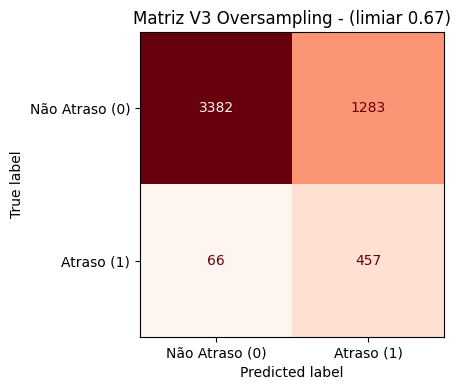

Resumo (teste):
- Proporcao Oversampling (Pos/Neg): 0.6000000000000001
- Limiar adotado: 0.67
- F1 atraso (Principal): 0.4039
- Precision atraso: 0.2626
- Recall atraso: 0.8738
- F2 atraso: 0.5963
- ROC-AUC atraso: 0.8845
- PR-AUC atraso: 0.5262


In [5]:
# Celula 5: treino final do modelo aplicando Oversampling no treino + avaliacao no teste.
# Aplica o oversampling no conjunto completo de treino com a melhor proporcao encontrada no Optuna
X_train_over, y_train_over = aplicar_oversampling(
    X_train, y_train,
    ratio=best_oversample_ratio_v3,
    random_state=4242
)

print(f"Resumo do Oversampling no Treino (Ratio Positivos/Negativos = {best_oversample_ratio_v3}):")
print(f" - Antes : {len(X_train):,} registros | Atrasos (1): {(y_train == 1).sum():,} ({(y_train == 1).mean():.2%}) | No Prazo (0): {(y_train == 0).sum():,}")
print(f" - Depois: {len(X_train_over):,} registros | Atrasos (1): {(y_train_over == 1).sum():,} ({(y_train_over == 1).mean():.2%}) | No Prazo (0): {(y_train_over == 0).sum():,}\n")

model_v3 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=4242,
    n_jobs=-1,
    tree_method="hist",
    enable_categorical=True,
    **best_params_v3,
)

# Sem early stopping: o teste nao participa do treino. Treinado na base balanceada com oversampling (X_train_over).
model_v3.fit(X_train_over, y_train_over, verbose=False)

# Probabilidade de atraso (classe 1) avaliada nas bases completas originais de treino e teste.
y_proba_v3_train = model_v3.predict_proba(X_train)[:, 1]
y_proba_v3_test = model_v3.predict_proba(X_test)[:, 1]

y_pred_v3_train = (y_proba_v3_train >= best_threshold_v3).astype(int)
y_pred_v3_test = (y_proba_v3_test >= best_threshold_v3).astype(int)

res_v3_train = metricas_atraso(y_train, y_pred_v3_train, y_proba_v3_train)
res_v3_test = metricas_atraso(y_test, y_pred_v3_test, y_proba_v3_test)
metricas_treino_v3 = metricas_gerais(y_train, y_pred_v3_train, y_proba_v3_train)
metricas_teste_v3 = metricas_gerais(y_test, y_pred_v3_test, y_proba_v3_test)

print("Metricas no teste (foco em atraso e F1-score):")
display(pd.DataFrame(pd.Series(res_v3_test, name="Teste")).round(4))

# Explicacao breve das metricas para leitura dos resultados.
print("\nComo interpretar as metricas:")
print("- f1_atraso: media harmonica entre precision e recall (metrica principal para comparacao dos modelos).")
print("- precision_atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- recall_atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- f2_atraso: semelhante ao F1, mas dando mais peso ao recall (bom para nao perder atrasos).")
print("- roc_auc_atraso: capacidade de separar atraso vs nao atraso em todos os limiares (quanto maior, melhor).")
print("- pr_auc_atraso: qualidade do modelo no trade-off precision x recall para classe rara (atraso).")

# Exibe matriz de confusao para visualizar erros da V3 no teste.
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_v3_test, cmap="Reds", ax=ax, colorbar=False,
    display_labels=["Não Atraso (0)", "Atraso (1)"]
)
ax.set_title(f"Matriz V3 Oversampling - (limiar {best_threshold_v3:.2f})")
plt.tight_layout()
plt.show()

print("Resumo (teste):")
print(f"- Proporcao Oversampling (Pos/Neg): {best_oversample_ratio_v3}")
print(f"- Limiar adotado: {best_threshold_v3:.2f}")
print(f"- F1 atraso (Principal): {res_v3_test['f1_atraso']:.4f}")
print(f"- Precision atraso: {res_v3_test['precision_atraso']:.4f}")
print(f"- Recall atraso: {res_v3_test['recall_atraso']:.4f}")
print(f"- F2 atraso: {res_v3_test['f2_atraso']:.4f}")
print(f"- ROC-AUC atraso: {res_v3_test['roc_auc_atraso']:.4f}")
print(f"- PR-AUC atraso: {res_v3_test['pr_auc_atraso']:.4f}")

In [6]:
# Celula 6: tabelas de metricas de atraso (classe 1).
print("=" * 120)
print("METRICAS DE ATRASO (CLASSE 1) - V3 OVERSAMPLING")
print("=" * 120)

print("\n(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)")

print("\n" + "-" * 120)
print("TREINO COMPLETO (ATRASO)")
print("-" * 120)
df_v3_train_atraso = pd.DataFrame(pd.Series(res_v3_train, name="Treino"))
display(df_v3_train_atraso.round(4))

print("\n" + "-" * 120)
print("TESTE (ATRASO)")
print("-" * 120)
df_v3_test_atraso = pd.DataFrame(pd.Series(res_v3_test, name="Teste"))
display(df_v3_test_atraso.round(4))

# ============================================================================
# RESUMO
# ============================================================================
print("RESUMO\n")
print("─" * 120 + "\n")
print(f"  Oversampling Ratio (Pos/Neg): {best_oversample_ratio_v3} | Limiar utilizado: {best_threshold_v3:.2f}")
print(
    f"  Treino - F1 (Atraso): {res_v3_train['f1_atraso']:.4f}, Precision (Atraso): {res_v3_train['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v3_train['recall_atraso']:.4f}, PR-AUC: {res_v3_train['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_treino_v3['ROC-AUC']:.4f}"
)
print(
    f"  Teste  - F1 (Atraso): {res_v3_test['f1_atraso']:.4f}, Precision (Atraso): {res_v3_test['precision_atraso']:.4f}, "
    f"Recall (Atraso): {res_v3_test['recall_atraso']:.4f}, PR-AUC: {res_v3_test['pr_auc_atraso']:.4f}, ROC-AUC: {metricas_teste_v3['ROC-AUC']:.4f}"
)


METRICAS DE ATRASO (CLASSE 1) - V3 OVERSAMPLING

(Accuracy, Precision, Recall, F1, F2, ROC-AUC, PR-AUC, Balanced Accuracy, MCC, Brier Score, Log Loss)

------------------------------------------------------------------------------------------------------------------------
TREINO COMPLETO (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Treino
accuracy_atraso,0.9465
precision_atraso,0.4200
recall_atraso,0.3628
f1_atraso,0.3893
f2_atraso,0.3730
roc_auc_atraso,0.8511
pr_auc_atraso,0.3754
balanced_accuracy_atraso,0.6691
mcc_atraso,0.3626
brier_score_atraso,0.1010



------------------------------------------------------------------------------------------------------------------------
TESTE (ATRASO)
------------------------------------------------------------------------------------------------------------------------


,Teste
accuracy_atraso,0.7400
precision_atraso,0.2626
recall_atraso,0.8738
f1_atraso,0.4039
f2_atraso,0.5963
roc_auc_atraso,0.8845
pr_auc_atraso,0.5262
balanced_accuracy_atraso,0.7994
mcc_atraso,0.3818
brier_score_atraso,0.2687


RESUMO

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  Oversampling Ratio (Pos/Neg): 0.6000000000000001 | Limiar utilizado: 0.67
  Treino - F1 (Atraso): 0.3893, Precision (Atraso): 0.4200, Recall (Atraso): 0.3628, PR-AUC: 0.3754, ROC-AUC: 0.8511
  Teste  - F1 (Atraso): 0.4039, Precision (Atraso): 0.2626, Recall (Atraso): 0.8738, PR-AUC: 0.5262, ROC-AUC: 0.8845


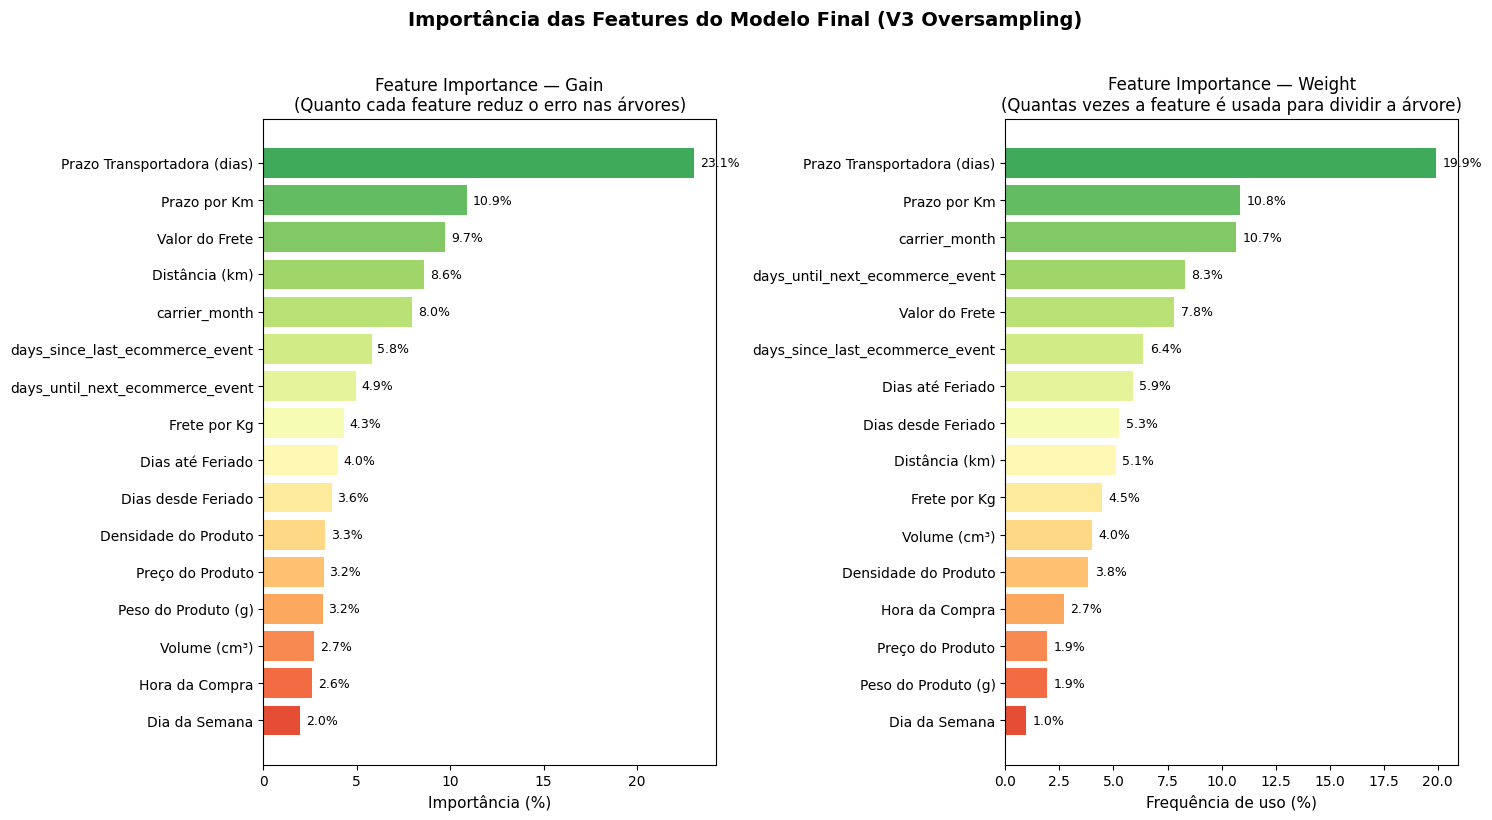


=== Resumo de importância ===
  Prazo Transportadora (dias)          Gain:  23.1%  |  Weight:  19.9%
  Prazo por Km                         Gain:  10.9%  |  Weight:  10.8%
  Valor do Frete                       Gain:   9.7%  |  Weight:   7.8%
  Distância (km)                       Gain:   8.6%  |  Weight:   5.1%
  carrier_month                        Gain:   8.0%  |  Weight:  10.7%
  days_since_last_ecommerce_event      Gain:   5.8%  |  Weight:   6.4%
  days_until_next_ecommerce_event      Gain:   4.9%  |  Weight:   8.3%
  Frete por Kg                         Gain:   4.3%  |  Weight:   4.5%
  Dias até Feriado                     Gain:   4.0%  |  Weight:   5.9%
  Dias desde Feriado                   Gain:   3.6%  |  Weight:   5.3%
  Densidade do Produto                 Gain:   3.3%  |  Weight:   3.8%
  Preço do Produto                     Gain:   3.2%  |  Weight:   1.9%
  Peso do Produto (g)                  Gain:   3.2%  |  Weight:   1.9%
  Volume (cm³)                         Gain:  

In [7]:
# Celula Extra: Grafico de Importancia das Features (Gain e Weight)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extraindo a importancia do modelo final (model_v3) treinado na celula anterior
importance_gain = model_v3.get_booster().get_score(importance_type="gain")
importance_weight = model_v3.get_booster().get_score(importance_type="weight")

df_imp = pd.DataFrame({
    "feature": list(importance_gain.keys()),
    "gain": list(importance_gain.values()),
}).sort_values("gain", ascending=True)

df_imp["weight"] = df_imp["feature"].map(importance_weight).fillna(0)

# Normalizar para percentual
df_imp["gain_pct"] = df_imp["gain"] / df_imp["gain"].sum() * 100
df_imp["weight_pct"] = df_imp["weight"] / df_imp["weight"].sum() * 100

# Renomear algumas features para pt-BR para ficar mais limpo
rename_map = {
    "prazo_transportadora_dias": "Prazo Transportadora (dias)",
    "distance_km": "Distância (km)",
    "freight_value": "Valor do Frete",
    "price": "Preço do Produto",
    "product_weight_g": "Peso do Produto (g)",
    "volume_cm3": "Volume (cm³)",
    "same_city": "Mesma Cidade",
    "seller_city": "Cidade do Vendedor",
    "customer_city": "Cidade do Cliente",
    "prazo_por_km": "Prazo por Km",
    "frete_por_kg": "Frete por Kg",
    "densidade_produto": "Densidade do Produto",
    "purchase_hour": "Hora da Compra",
    "purchase_day_of_week": "Dia da Semana",
    "category_name": "Categoria do Produto",
    "days_until_next_holiday": "Dias até Feriado",
    "days_since_last_holiday": "Dias desde Feriado",
    "purchase_month": "Mês da Compra",
}
df_imp["label"] = df_imp["feature"].map(rename_map).fillna(df_imp["feature"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))

# Grafico de Gain
colors1 = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(df_imp)))
ax1.barh(df_imp["label"], df_imp["gain_pct"], color=colors1)
ax1.set_xlabel("Importância (%)", fontsize=11)
ax1.set_title("Feature Importance — Gain\n(Quanto cada feature reduz o erro nas árvores)", fontsize=12)
for i, val in enumerate(df_imp["gain_pct"]):
    ax1.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)

# Grafico de Weight
df_imp2 = df_imp.sort_values("weight_pct", ascending=True)
colors2 = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(df_imp2)))
ax2.barh(df_imp2["label"], df_imp2["weight_pct"], color=colors2)
ax2.set_xlabel("Frequência de uso (%)", fontsize=11)
ax2.set_title("Feature Importance — Weight\n(Quantas vezes a feature é usada para dividir a árvore)", fontsize=12)
for i, val in enumerate(df_imp2["weight_pct"]):
    ax2.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)

plt.suptitle("Importância das Features do Modelo Final (V3 Oversampling)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Print tabela resumo
print("\n=== Resumo de importância ===")
df_imp_sorted = df_imp.sort_values("gain_pct", ascending=False)
for _, row in df_imp_sorted.iterrows():
    print(f"  {row['label']:35s}  Gain: {row['gain_pct']:5.1f}%  |  Weight: {row['weight_pct']:5.1f}%")

In [8]:
# Célula de exportação para deploy: modelo + pré-processamento completo.
# A API prevê no momento da coleta pela transportadora e recebe somente dados brutos.
import pickle

raw_columns = [
    "purchase_date", "purchase_time", "carrier_datetime", "estimated_delivery_datetime",
    "price", "freight_value", "product_weight_g", "height_cm", "width_cm", "length_cm",
    "distance_km", "same_city", "customer_city", "seller_city", "category_name",
]

artefato_modelo = {
    "modelo": model_v3,
    "limiar": float(best_threshold_v3),
    "oversample_ratio": float(best_oversample_ratio_v3),
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "scaler": scaler,
    "schema_version": 4,
    "inference_moment": "carrier_collection",
    "raw_columns": raw_columns,
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],
}

with open("xgboost_lastmile_model_v3_oversampling.pkl", "wb") as file:
    pickle.dump(artefato_modelo, file)

# CSV bruto para testar o mesmo contrato usado pela tela individual e pelo lote.
# Amostra organica e balanceada com 40% de atrasos (target=1) diluidos no tempo.
n_registros = 150
n_atrasos = int(n_registros * 0.40)   # 60 pedidos que atrasaram
n_no_prazo = n_registros - n_atrasos  # 90 pedidos no prazo

df_test_full = df.loc[test_mask].copy()
df_test_full["target_real_atraso"] = y_test.values

df_atrasos = df_test_full[df_test_full["target_real_atraso"] == 1]
df_no_prazo = df_test_full[df_test_full["target_real_atraso"] == 0]

# 1. 60 atrasos distribuidos uniformemente ao longo do periodo de teste
idx_atrasos = np.round(np.linspace(0, len(df_atrasos) - 1, n_atrasos)).astype(int)
selected_atrasos = df_atrasos.iloc[idx_atrasos]

# 2. 90 pedidos no prazo pareados temporalmente para diluir organicamente os atrasos
used_indices = set()
selected_no_prazo_indices = []

for dt in selected_atrasos["order_delivered_carrier_date"]:
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

for dt in selected_atrasos["order_delivered_carrier_date"][::2]:
    if len(selected_no_prazo_indices) >= n_no_prazo:
        break
    diffs = (df_no_prazo["order_delivered_carrier_date"] - dt).abs()
    for c in diffs.sort_values().index:
        if c not in used_indices:
            used_indices.add(c)
            selected_no_prazo_indices.append(c)
            break

selected_no_prazo = df_no_prazo.loc[selected_no_prazo_indices]

# 3. Concatena e ordena estritamente por ordem cronologica da coleta pela transportadora
test_rows = pd.concat([selected_atrasos, selected_no_prazo]).sort_values("order_delivered_carrier_date").reset_index(drop=True)

df_export = pd.DataFrame({
    "purchase_date": test_rows["order_purchase_timestamp"].dt.strftime("%Y-%m-%d"),
    "purchase_time": test_rows["order_purchase_timestamp"].dt.strftime("%H:%M"),
    "carrier_datetime": test_rows["order_delivered_carrier_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "estimated_delivery_datetime": test_rows["order_estimated_delivery_date"].dt.strftime("%Y-%m-%dT%H:%M"),
    "price": test_rows["price"],
    "freight_value": test_rows["freight_value"],
    "product_weight_g": test_rows["product_weight_g"],
    # A base não possui dimensões individuais; 1 × 1 × volume preserva o volume original.
    "height_cm": 1.0,
    "width_cm": 1.0,
    "length_cm": test_rows["volume_cm3"],
    "distance_km": test_rows["distance_km"],
    "same_city": test_rows["same_city"],
    "customer_city": test_rows["customer_city"].fillna("Unknown"),
    "seller_city": test_rows["seller_city"].fillna("Unknown"),
    "category_name": test_rows["category_name"].fillna("Unknown"),
    "target_real_atraso": test_rows["target_real_atraso"].values,
})

nome_arquivo_csv = f"amostra_teste_{n_registros}_pedidos.csv"
df_export.to_csv(nome_arquivo_csv, index=False)
df_export.to_csv("amostra_teste_100_pedidos.csv", index=False) # Compatibilidade

print("[Exportação] Artefato completo salvo: xgboost_lastmile_model_v3_oversampling.pkl")
print(f"[Exportação] CSV bruto salvo: {nome_arquivo_csv} ({len(df_export)} pedidos: {df_export['target_real_atraso'].sum()} atrasos ({df_export['target_real_atraso'].mean():.0%}) e {(df_export['target_real_atraso'] == 0).sum()} no prazo)")

[Exportação] Artefato completo salvo: xgboost_lastmile_model_v3_oversampling.pkl
[Exportação] CSV bruto salvo: amostra_teste_150_pedidos.csv (150 pedidos: 60 atrasos (40%) e 90 no prazo)


In [9]:
# Celula 9: Diagnostico detalhado por faixas de prazo da transportadora (Treino vs Teste)
df_diag_train = pd.DataFrame({
    "dias": X_train["prazo_transportadora_dias"].values,
    "atraso": y_train.values,
    "pred_modelo": y_pred_v3_train,
})

df_diag_test = pd.DataFrame({
    "dias": X_test["prazo_transportadora_dias"].values,
    "atraso": y_test.values,
    "pred_modelo": y_pred_v3_test,
})

def classificar_macro(d):
    if d < 0:
        return "< 0 dias (Ja atrasado na coleta)"
    elif d == 0:
        return "0 dias (Vence no dia da coleta)"
    else:
        return "> 0 dias (Com prazo restante)"

ordem_macro = [
    "< 0 dias (Ja atrasado na coleta)",
    "0 dias (Vence no dia da coleta)",
    "> 0 dias (Com prazo restante)",
]

df_diag_train["macro"] = pd.Categorical(df_diag_train["dias"].map(classificar_macro), categories=ordem_macro, ordered=True)
df_diag_test["macro"] = pd.Categorical(df_diag_test["dias"].map(classificar_macro), categories=ordem_macro, ordered=True)

def resumo_macro(df_d, prefixo):
    grp = df_d.groupby("macro", observed=False).agg(
        pedidos=("atraso", "count"),
        atrasos=("atraso", "sum"),
    )
    total_ped = len(df_d)
    total_atr = df_d["atraso"].sum()
    res = pd.DataFrame(index=grp.index)
    res[f"{prefixo}: Pedidos"] = grp["pedidos"]
    res[f"{prefixo}: % Total"] = (grp["pedidos"] / total_ped * 100).round(2)
    res[f"{prefixo}: Atrasos"] = grp["atrasos"]
    res[f"{prefixo}: % Atrasos"] = (grp["atrasos"] / total_atr * 100).round(2)
    res[f"{prefixo}: Taxa Atraso (%)"] = (grp["atrasos"] / grp["pedidos"].replace(0, np.nan) * 100).fillna(0).round(2)
    return res

print("=" * 120)
print("1. RESUMO MACRO: PEDIDOS COM PRAZO ESGOTADO (< 0 DIAS E 0 DIAS) VS COM PRAZO RESTANTE (> 0 DIAS)")
print("=" * 120)
df_macro_comp = pd.concat([resumo_macro(df_diag_train, "Treino"), resumo_macro(df_diag_test, "Teste")], axis=1)
display(df_macro_comp)

def classificar_faixa(d):
    if d < -10: return "< -10 dias (Atraso critico)"
    elif d <= -6: return "-10 a -6 dias (Atraso severo)"
    elif d <= -1: return "-5 a -1 dias (Ja atrasado na coleta)"
    elif d == 0: return "0 dias (Vence no dia da coleta)"
    elif d == 1: return "1 dia (Urgencia maxima)"
    elif d == 2: return "2 dias (Urgencia alta)"
    elif d <= 5: return "3 a 5 dias (Prazo curto)"
    elif d <= 10: return "6 a 10 dias (Prazo moderado)"
    elif d <= 15: return "11 a 15 dias (Prazo padrao)"
    elif d <= 20: return "16 a 20 dias (Prazo confortavel)"
    elif d <= 30: return "21 a 30 dias (Prazo longo)"
    else: return "> 30 dias (Prazo muito longo)"

ordem_faixas = [
    "< -10 dias (Atraso critico)",
    "-10 a -6 dias (Atraso severo)",
    "-5 a -1 dias (Ja atrasado na coleta)",
    "0 dias (Vence no dia da coleta)",
    "1 dia (Urgencia maxima)",
    "2 dias (Urgencia alta)",
    "3 a 5 dias (Prazo curto)",
    "6 a 10 dias (Prazo moderado)",
    "11 a 15 dias (Prazo padrao)",
    "16 a 20 dias (Prazo confortavel)",
    "21 a 30 dias (Prazo longo)",
    "> 30 dias (Prazo muito longo)",
]

df_diag_train["faixa"] = pd.Categorical(df_diag_train["dias"].map(classificar_faixa), categories=ordem_faixas, ordered=True)
df_diag_test["faixa"] = pd.Categorical(df_diag_test["dias"].map(classificar_faixa), categories=ordem_faixas, ordered=True)

def resumo_faixa(df_d, prefixo):
    grp = df_d.groupby("faixa", observed=False).agg(
        pedidos=("atraso", "count"),
        atrasos=("atraso", "sum"),
        previstos=("pred_modelo", "sum"),
        tp=("atraso", lambda s: int(((s == 1) & (df_d.loc[s.index, "pred_modelo"] == 1)).sum()))
    )
    total_ped = len(df_d)
    total_atr = df_d["atraso"].sum()
    res = pd.DataFrame(index=grp.index)
    res[f"{prefixo}: Pedidos"] = grp["pedidos"]
    res[f"{prefixo}: % do Split"] = (grp["pedidos"] / total_ped * 100).round(2)
    res[f"{prefixo}: Atrasos Reais"] = grp["atrasos"]
    res[f"{prefixo}: % dos Atrasos"] = (grp["atrasos"] / total_atr * 100).round(2)
    res[f"{prefixo}: Taxa Atraso (%)"] = (grp["atrasos"] / grp["pedidos"].replace(0, np.nan) * 100).fillna(0).round(2)
    res[f"{prefixo}: Previstos Atraso (Mod)"] = grp["previstos"]
    res[f"{prefixo}: Recall Modelo (%)"] = (grp["tp"] / grp["atrasos"].replace(0, np.nan) * 100).round(2)
    return res

print("\n" + "=" * 120)
print("2. TABELA DETALHADA POR FAIXAS DE DIAS RESTANTES (TREINO vs TESTE)")
print("=" * 120)
tb_faixa_tr = resumo_faixa(df_diag_train, "Treino")
tb_faixa_te = resumo_faixa(df_diag_test, "Teste")

print("\n--- TREINO: FAIXAS DE PRAZO DA TRANSPORTADORA ---")
display(tb_faixa_tr)

print("\n--- TESTE: FAIXAS DE PRAZO DA TRANSPORTADORA ---")
display(tb_faixa_te)

1. RESUMO MACRO: PEDIDOS COM PRAZO ESGOTADO (< 0 DIAS E 0 DIAS) VS COM PRAZO RESTANTE (> 0 DIAS)


,Treino: Pedidos,Treino: % Total,Treino: Atrasos,Treino: % Atrasos,Treino: Taxa Atraso (%),Teste: Pedidos,Teste: % Total,Teste: Atrasos,Teste: % Atrasos,Teste: Taxa Atraso (%)
macro,,,,,,,,,,
< 0 dias (Ja atrasado na coleta),0,0.00,0,0.00,0.00,0,0.00,0,0.00,0.00
0 dias (Vence no dia da coleta),36,0.12,36,2.63,100.00,66,1.27,66,12.62,100.00
> 0 dias (Com prazo restante),29068,99.88,1331,97.37,4.58,5122,98.73,457,87.38,8.92



2. TABELA DETALHADA POR FAIXAS DE DIAS RESTANTES (TREINO vs TESTE)

--- TREINO: FAIXAS DE PRAZO DA TRANSPORTADORA ---


,Treino: Pedidos,Treino: % do Split,Treino: Atrasos Reais,Treino: % dos Atrasos,Treino: Taxa Atraso (%),Treino: Previstos Atraso (Mod),Treino: Recall Modelo (%)
faixa,,,,,,,
< -10 dias (Atraso critico),0,0.00,0,0.00,0.00,0,NaN
-10 a -6 dias (Atraso severo),0,0.00,0,0.00,0.00,0,NaN
-5 a -1 dias (Ja atrasado na coleta),0,0.00,0,0.00,0.00,0,NaN
0 dias (Vence no dia da coleta),36,0.12,36,2.63,100.00,36,100.00
1 dia (Urgencia maxima),40,0.14,40,2.93,100.00,40,100.00
2 dias (Urgencia alta),62,0.21,39,2.85,62.90,62,100.00
3 a 5 dias (Prazo curto),286,0.98,118,8.63,41.26,280,98.31
6 a 10 dias (Prazo moderado),5123,17.60,373,27.29,7.28,405,39.41
11 a 15 dias (Prazo padrao),9398,32.29,435,31.82,4.63,351,26.21



--- TESTE: FAIXAS DE PRAZO DA TRANSPORTADORA ---


,Teste: Pedidos,Teste: % do Split,Teste: Atrasos Reais,Teste: % dos Atrasos,Teste: Taxa Atraso (%),Teste: Previstos Atraso (Mod),Teste: Recall Modelo (%)
faixa,,,,,,,
< -10 dias (Atraso critico),0,0.00,0,0.00,0.00,0,NaN
-10 a -6 dias (Atraso severo),0,0.00,0,0.00,0.00,0,NaN
-5 a -1 dias (Ja atrasado na coleta),0,0.00,0,0.00,0.00,0,NaN
0 dias (Vence no dia da coleta),66,1.27,66,12.62,100.00,66,100.00
1 dia (Urgencia maxima),125,2.41,122,23.33,97.60,125,100.00
2 dias (Urgencia alta),255,4.92,84,16.06,32.94,255,100.00
3 a 5 dias (Prazo curto),856,16.50,149,28.49,17.41,796,94.63
6 a 10 dias (Prazo moderado),1929,37.18,89,17.02,4.61,484,48.31
11 a 15 dias (Prazo padrao),1295,24.96,12,2.29,0.93,14,8.33
